In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [84]:
df = pd.read_csv('SMSSpamCollection', sep = '\t', header = None)

In [85]:
df.columns = ['label', 'message']

In [86]:
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [87]:
print("Rows and columns:", df.shape)
print('\n column names:' , df.columns.tolist())
print(df.dtypes)

Rows and columns: (5572, 2)

 column names: ['label', 'message']
label      object
message    object
dtype: object


In [88]:
df.tail()

,label,message
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...
5571,ham,Rofl. Its true to its name


In [89]:
df.isnull().sum()

label      0
message    0
dtype: int64

In [90]:
print("duplicate rows:", df.duplicated().sum())
print("Duplicate message: ", df['message'].duplicated().sum())

duplicate rows: 403
Duplicate message:  403


In [91]:
df['label'].value_counts()

label
ham     4825
spam     747
Name: count, dtype: int64

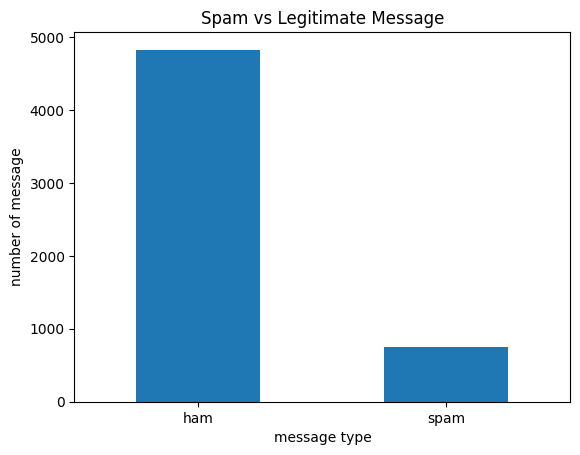

In [92]:
df['label'].value_counts().plot(kind = 'bar')
plt.title('Spam vs Legitimate Message')
plt.xlabel("message type")
plt.ylabel('number of message')
plt.xticks(rotation=0)
plt.show()

In [93]:
print((df['label'].value_counts(normalize=True) * 100).round(2))

label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


In [94]:
df['message_length'] = df["message"].str.len()
print(df.groupby("label")["message_length"].describe())

        count        mean        std   min    25%    50%    75%    max
label                                                                 
ham    4825.0   71.482487  58.440652   2.0   33.0   52.0   93.0  910.0
spam    747.0  138.670683  28.873603  13.0  133.0  149.0  157.0  223.0


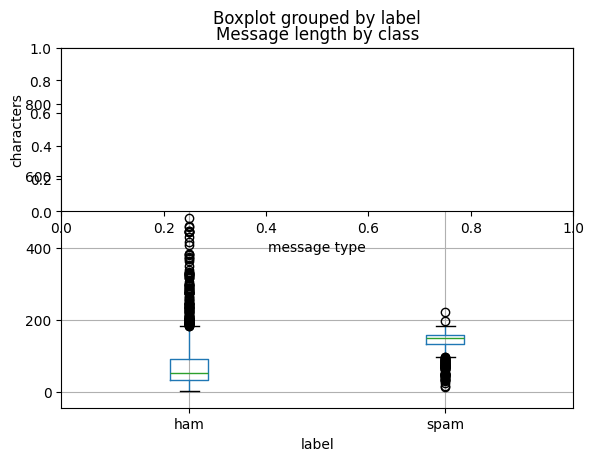

In [95]:
df.boxplot(column="message_length", by="label")
plt.title("Message length by class")
plt.subplot(2,1,1)
plt.xlabel("message type")
plt.ylabel("characters")
plt.show()

In [96]:
df = df.dropna(subset=["label", "message"])
df = df.drop_duplicates(subset=["label", "message"])
df = df[df["label"].isin(["ham", "spam"])].copy()

print("cleaned Dataset:", df.shape)
print(df["label"].value_counts())


cleaned Dataset: (5169, 3)
label
ham     4516
spam     653
Name: count, dtype: int64


In [97]:
X = df['message']
y = df['label']

In [98]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(X, y , test_size = 0.2, random_state = 42, stratify=y)
print("Training Samples:", len(x_train))
print("Testing samples:", len(x_test))

Training Samples: 4135
Testing samples: 1034


In [118]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)


In [120]:

x_train_tfidf = tfidf.fit_transform(x_train)

print("Training matrix:", x_train_tfidf.shape)


Training matrix: (4135, 10188)


In [122]:

x_test_tfidf = tfidf.transform(x_test)

print("Testing matrix:", x_test_tfidf.shape)


Testing matrix: (1034, 10188)


In [138]:

from sklearn.naive_bayes import MultinomialNB


In [139]:
# Tuned alpha=0.2 to alleviate class imbalance and prevent minority class suppression
model = MultinomialNB(alpha=0.2)


In [140]:
model.fit(x_train_tfidf, y_train)
print("Training Complete!")

Training Complete!


In [141]:
y_pred = model.predict(x_test_tfidf)
print(y_pred[:10])

['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']


In [142]:
from sklearn.metrics import accuracy_score

In [143]:
accuracy = accuracy_score(y_test, y_pred)
print("Test Accuracy:", round(accuracy * 100,2), "%")

Test Accuracy: 96.23 %


In [144]:
from sklearn.metrics import classification_report

In [145]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       1.00      0.89      0.94       131

    accuracy                           0.99      1034
   macro avg       0.99      0.95      0.97      1034
weighted avg       0.99      0.99      0.99      1034


In [146]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

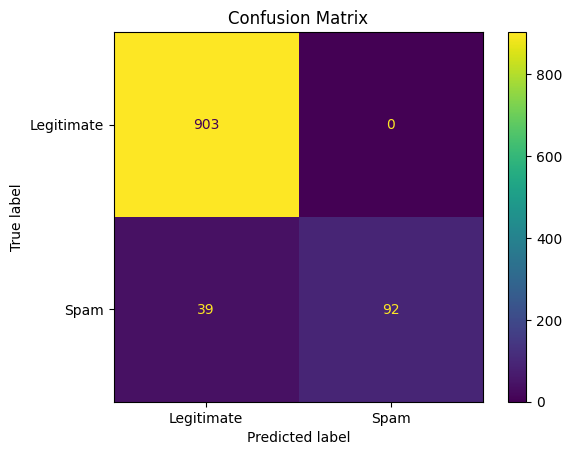

In [147]:
cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Spam"]
).plot()

plt.title("Confusion Matrix")
plt.show()

In [148]:
messages = [
    "Congratulations! You won a free prize. Call now!",
    "Hey, are we meeting for lunch today?"
]

messages_tfidf = tfidf.transform(messages)
predictions = model.predict(messages_tfidf)

for message, prediction in zip(messages, predictions):
    print("Message:", message)
    print("Prediction:", prediction)
    print()

Message: Congratulations! You won a free prize. Call now!
Prediction: spam

Message: Hey, are we meeting for lunch today?
Prediction: ham



In [149]:

import joblib

joblib.dump(model, "spam_model.pkl")
joblib.dump(tfidf, "tfidf.pkl")


['tfidf.pkl']